<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter7/pendulum_elevator_trajectories.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Pendulum Trajectories in an Accelerating Elevator.

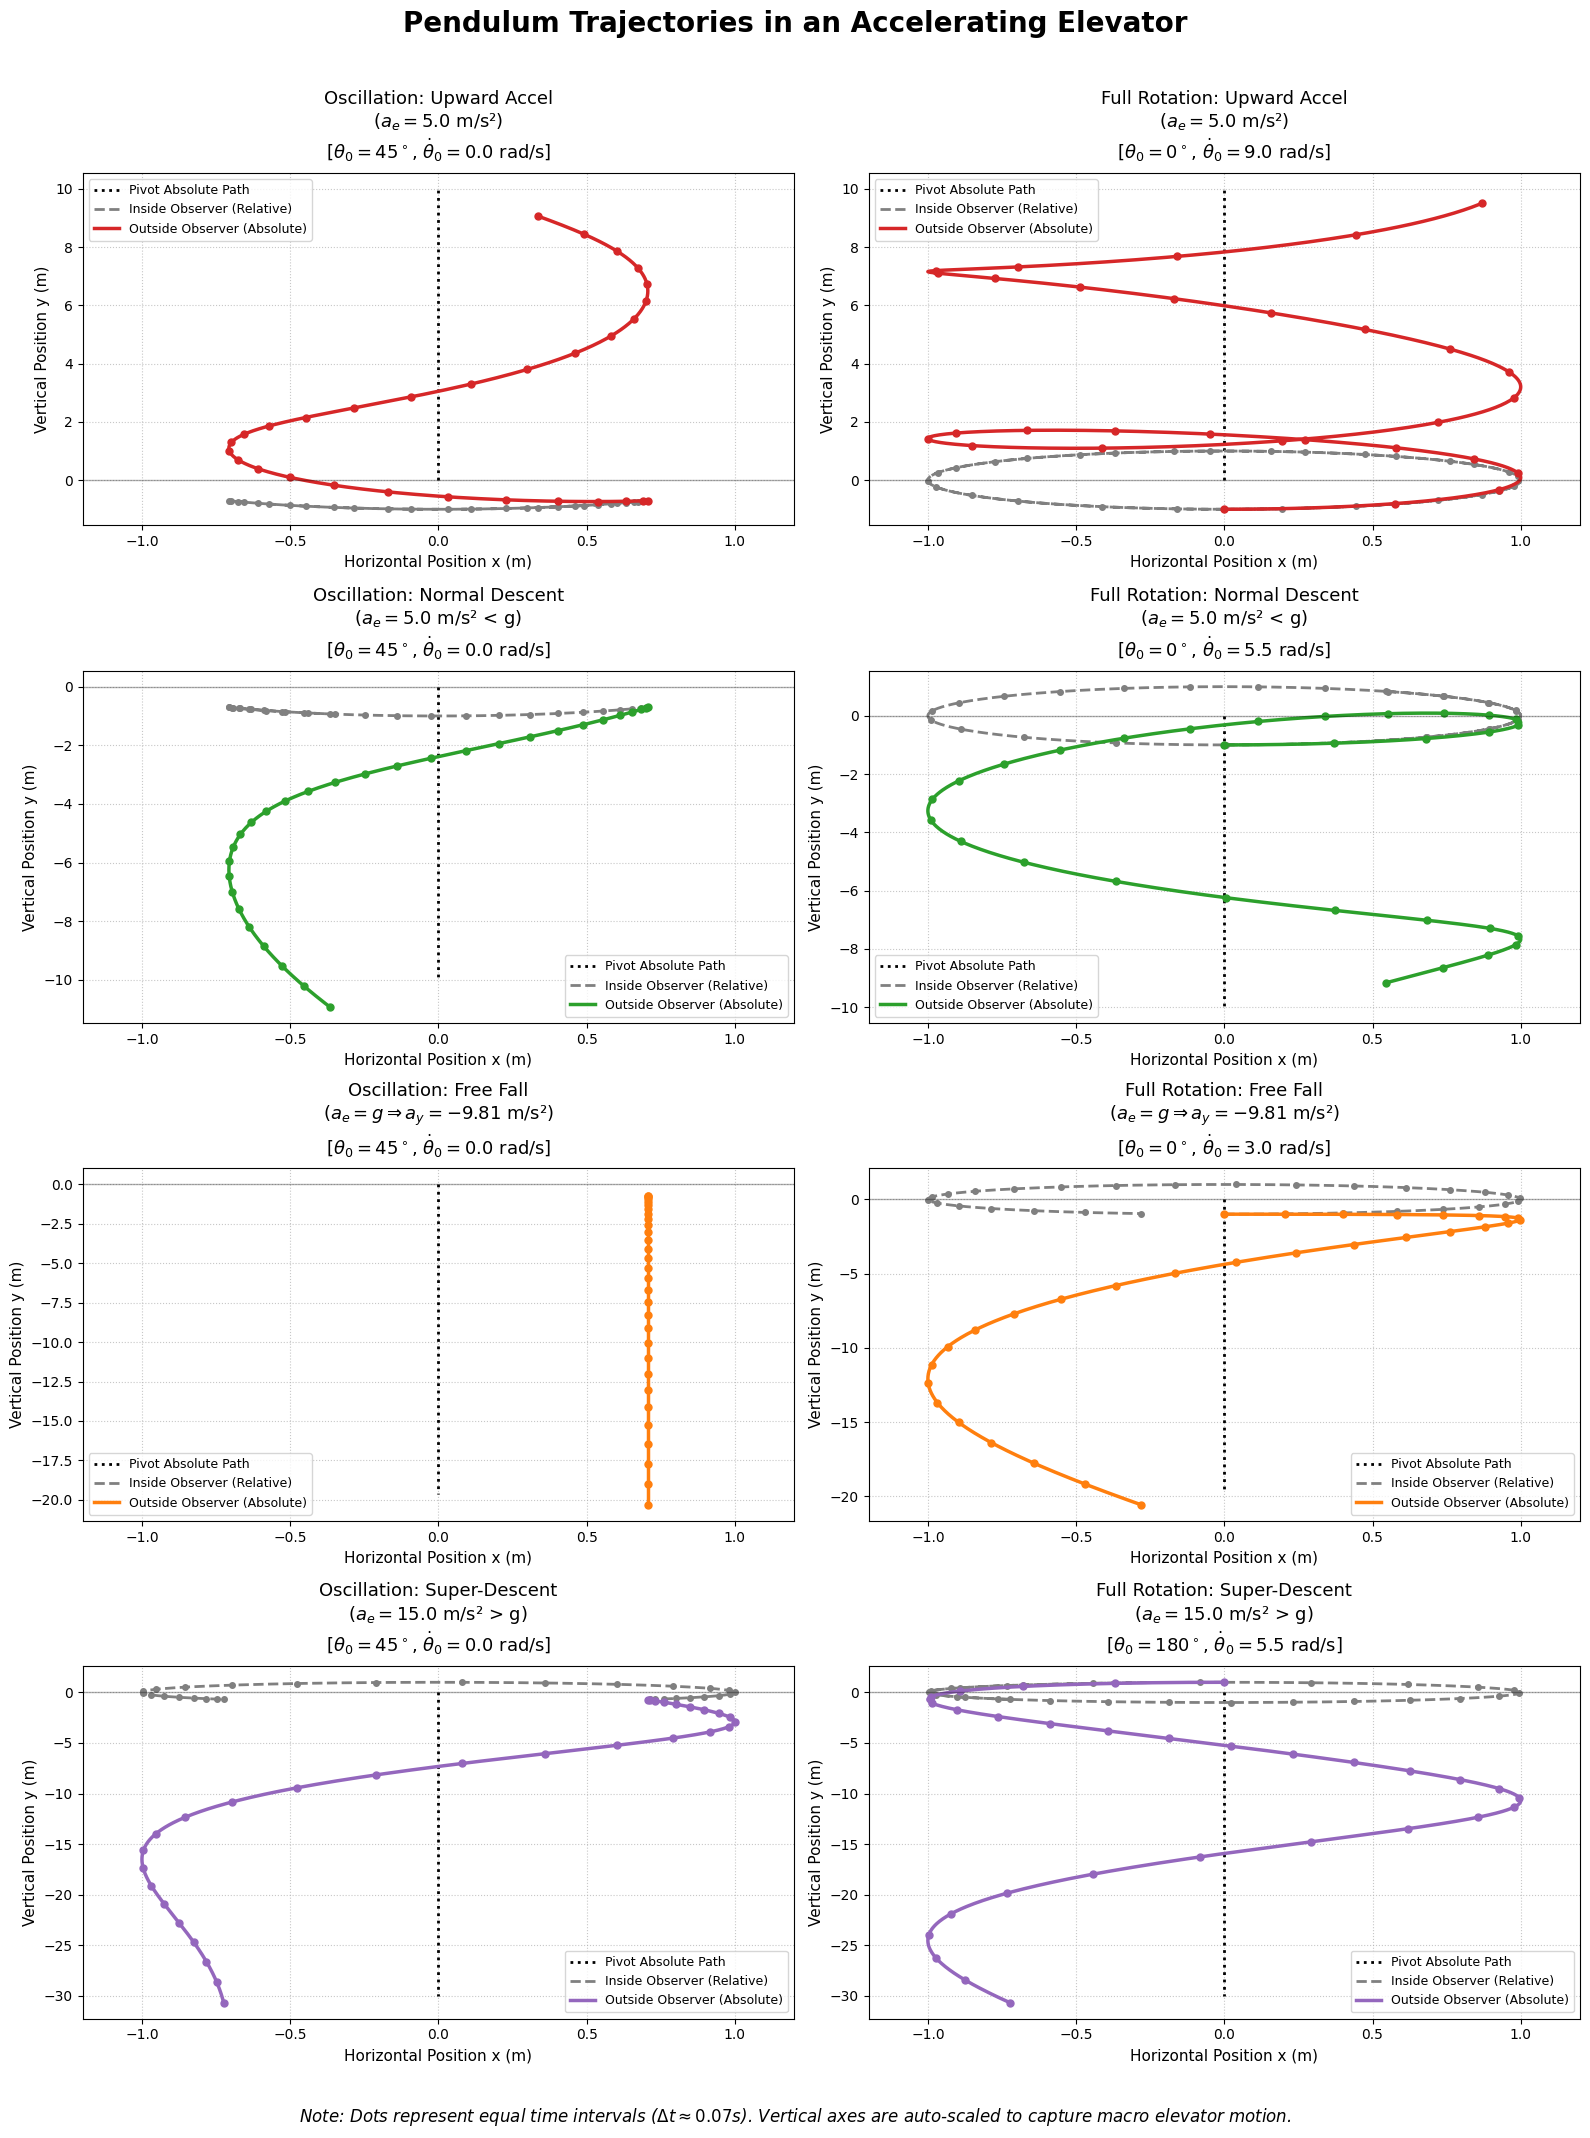

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Physics Constants
g = 9.81        # Acceleration due to gravity (m/s^2)
l = 1.0         # Length of the pendulum string (m)

# Time span for the simulation
t_max = 2.0
t_span = (0, t_max)
t_eval = np.linspace(t_span[0], t_span[1], 1000)
t_markers = np.linspace(t_span[0], t_span[1], 30) # Increased dots for better loop visibility

# Scenarios: (Title, Kinematic Acceleration a_y in m/s^2, Color, Initial Theta, Initial Omega)
# Oscillation: Released from rest at 45 degrees.
# Rotation: Given enough initial angular velocity to complete a full loop.
scenarios = [
    # Row 1: Upward Acceleration
    ("Oscillation: Upward Accel\n($a_e = 5.0$ m/s²)", 5.0, "#d62728", np.pi/4, 0.0),
    ("Full Rotation: Upward Accel\n($a_e = 5.0$ m/s²)", 5.0, "#d62728", 0.0, 9.0),

    # Row 2: Downward Normal Descent
    ("Oscillation: Normal Descent\n($a_e = 5.0$ m/s² < g)", -5.0, "#2ca02c", np.pi/4, 0.0),
    ("Full Rotation: Normal Descent\n($a_e = 5.0$ m/s² < g)", -5.0, "#2ca02c", 0.0, 5.5),

    # Row 3: Free Fall
    ("Oscillation: Free Fall\n($a_e = g \\Rightarrow a_y = -9.81$ m/s²)", -9.81, "#ff7f0e", np.pi/4, 0.0),
    ("Full Rotation: Free Fall\n($a_e = g \\Rightarrow a_y = -9.81$ m/s²)", -9.81, "#ff7f0e", 0.0, 3.0),

    # Row 4: Super-Accelerated Descent
    ("Oscillation: Super-Descent\n($a_e = 15.0$ m/s² > g)", -15.0, "#9467bd", np.pi/4, 0.0),
    ("Full Rotation: Super-Descent\n($a_e = 15.0$ m/s² > g)", -15.0, "#9467bd", np.pi, 5.5)
]

fig, axs = plt.subplots(4, 2, figsize=(16, 22))
fig.suptitle("Pendulum Trajectories in an Accelerating Elevator", fontsize=20, fontweight='bold', y=0.97)
axs = axs.flatten()

for idx, (title, ay, color, th0, om0) in enumerate(scenarios):
    ax = axs[idx]

    # 1. Define the Ordinary Differential Equation (ODE) for the pendulum
    # The equation of motion is: theta_ddot = - (g + a_y) / l * sin(theta)
    def pendulum_ode(t, state, current_ay):
        theta, omega = state
        dtheta = omega
        domega = -(g + current_ay) / l * np.sin(theta)
        return [dtheta, domega]

    # 2. Solve the ODE numerically
    sol = solve_ivp(pendulum_ode, t_span, [th0, om0], t_eval=t_eval, method='RK45', args=(ay,))
    theta_t = sol.y[0]

    # Solve specifically for the marker points to overlay time-dots
    sol_markers = solve_ivp(pendulum_ode, t_span, [th0, om0], t_eval=t_markers, method='RK45', args=(ay,))
    theta_m = sol_markers.y[0]

    # 3. Calculate Non-Inertial (Inside Observer) Trajectory
    # Origin is fixed at the pivot (0,0)
    x_rel = l * np.sin(theta_t)
    y_rel = -l * np.cos(theta_t)

    x_rel_m = l * np.sin(theta_m)
    y_rel_m = -l * np.cos(theta_m)

    # 4. Calculate Inertial (Outside Observer) Trajectory
    # Pivot moves vertically according to y = 0.5 * a_y * t^2
    y_pivot = 0.5 * ay * t_eval**2
    x_abs = x_rel                             # X-position is the same in both frames
    y_abs = y_pivot + y_rel                   # Y-position has the elevator's macro motion added

    y_pivot_m = 0.5 * ay * t_markers**2
    x_abs_m = x_rel_m
    y_abs_m = y_pivot_m + y_rel_m

    # 5. Plotting the Trajectories
    # Plot the pivot's absolute path (the elevator ceiling)
    ax.plot(np.zeros_like(t_eval), y_pivot, label="Pivot Absolute Path", color='black', linestyle='dotted', linewidth=2)

    # Plot the Non-Inertial (Inside) path
    ax.plot(x_rel, y_rel, label="Inside Observer (Relative)", color='gray', linestyle='dashed', linewidth=2)
    ax.plot(x_rel_m, y_rel_m, 'o', color='gray', markersize=4) # Time markers

    # Plot the Inertial (Outside) path
    ax.plot(x_abs, y_abs, label="Outside Observer (Absolute)", color=color, linewidth=2.5)
    ax.plot(x_abs_m, y_abs_m, 'o', color=color, markersize=5) # Time markers

    # Dynamically add the initial starting conditions to the plot title
    th0_deg = int(np.round(np.degrees(th0)))
    detailed_title = f"{title}\n[$\\theta_0 = {th0_deg}^\\circ$, $\\dot{{\\theta}}_0 = {om0}$ rad/s]"

    ax.set_title(detailed_title, fontsize=13, pad=10)
    ax.set_xlabel("Horizontal Position x (m)", fontsize=11)
    ax.set_ylabel("Vertical Position y (m)", fontsize=11)

    # Add a horizontal line at y=0 representing the starting pivot height
    ax.axhline(0, color='black', linewidth=1, alpha=0.3)

    # Auto-scale x-axis to keep swings visible, but allow y-axis to stretch
    ax.set_xlim(-1.2, 1.2)
    ax.grid(True, linestyle=':', alpha=0.7)

    # Legend placement
    ax.legend(loc='best', fontsize=9)

plt.figtext(0.5, 0.01, "Note: Dots represent equal time intervals ($\\Delta t \\approx 0.07s$). Vertical axes are auto-scaled to capture macro elevator motion.",
            ha="center", fontsize=12, style='italic')

plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()